# YESNO Audio Classification
### Digital Speech Processing — Task 8

This notebook builds a complete pipeline for classifying the spoken words **"Yes"** and **"No"** in the OpenSLR YESNO dataset. It covers audio loading, visualisation, word segmentation, MFCC feature extraction, a recording-level train/test split, four classifiers, and a full evaluation.

**How to run:** open the notebook in Google Colab and choose *Runtime → Run all*. The dataset is downloaded automatically. No result in this notebook is typed in by hand: every number and plot is computed by the code.

**Contents**

1. Introduction and Objectives
2. Environment Setup
3. Dataset: OpenSLR YESNO
4. Audio Loading, Waveform, Spectrogram and MFCC
5. Audio Segmentation into Words
6. Recording-Level Train/Test Split
7. Feature Extraction and Dataset Statistics
8. Classification Models
9. Training and Evaluation
10. Visualisation of Results
11. Results and Comparison
12. Limitations
13. Conclusion
14. References

## 1. Introduction and Objectives

Speech recognition systems must first decide *which word* was spoken. The YESNO dataset is a very small and simple version of this problem: every recording contains eight spoken words, and each word is either "yes" or "no". This makes it a good teaching example for the whole pipeline of a speech classifier.

**Objectives**

1. Load, play and visualise a speech recording (waveform and spectrogram).
2. Extract 13 Mel-frequency cepstral coefficients (MFCCs) and visualise them.
3. Split each recording into individual words with energy-based segmentation (`librosa.effects.split`).
4. Describe every word with 26 features (the mean and the standard deviation of each of the 13 MFCCs).
5. Split the data **by recording** (not by word) into training and test sets.
6. Train and compare four classifiers: SVM, Neural Network, Random Forest and KNN.
7. Evaluate them with accuracy, precision, recall, F1-score, classification reports and confusion matrices.
8. Discuss the results and the limitations honestly.

## 2. Environment Setup

The next cell imports all libraries and defines every parameter in one place, so that the experiment can be reproduced and changed easily. A fixed random seed (`RANDOM_STATE = 42`) is used wherever randomness appears.

In [18]:
# ---------------------------------------------------------------
# 2. Imports and global parameters
# ---------------------------------------------------------------
import os
import glob
import random
import tarfile
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import librosa.display
import sklearn
from IPython.display import Audio, display

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

# ----- Reproducibility -----
RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

# ----- Dataset parameters -----
DATA_URL = "https://www.openslr.org/resources/1/waves_yesno.tar.gz"
DATA_DIR = "data"
ARCHIVE_PATH = os.path.join(DATA_DIR, "waves_yesno.tar.gz")
EXPECTED_RECORDINGS = 60
WORDS_PER_RECORDING = 8
CLASS_NAMES = {0: "No", 1: "Yes"}      # label coding used in the file names

# ----- Segmentation parameters (required by the assignment) -----
TOP_DB = 25
FRAME_LENGTH = 512
HOP_LENGTH = 128

# ----- MFCC parameters -----
N_MFCC = 13
N_FFT = 512        # window size for the spectrum (same as FRAME_LENGTH)
N_MELS = 40        # number of Mel bands (the audio is only 8 kHz, so 40 is enough)

# ----- Split parameters -----
TEST_SIZE = 0.25

# ----- Output folder for saved tables and figures -----
RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)

plt.rcParams["figure.dpi"] = 100
warnings.filterwarnings("ignore", category=FutureWarning)

print("librosa:", librosa.__version__, "| scikit-learn:", sklearn.__version__, "| numpy:", np.__version__)

librosa: 0.11.0 | scikit-learn: 1.6.1 | numpy: 2.4.6


## 3. Dataset: OpenSLR YESNO

According to the dataset page on OpenSLR (resource 1), the dataset contains **60 recordings** sampled at **8 kHz**. In each recording a speaker says **eight words**, and every word is either the Hebrew word for "yes" or the Hebrew word for "no". The file name stores the sequence of the eight labels, for example `0_0_1_1_0_1_0_1.wav`, where **0 = no** and **1 = yes**.

The next cell downloads and extracts the archive automatically. If the files already exist, the download is skipped.

In [19]:
# ---------------------------------------------------------------
# 3.1 Download and extract the dataset (skipped if already present)
# ---------------------------------------------------------------
def list_wav_files():
    """Return all .wav files below DATA_DIR in a stable (sorted) order."""
    return sorted(glob.glob(os.path.join(DATA_DIR, "**", "*.wav"), recursive=True))

os.makedirs(DATA_DIR, exist_ok=True)

if len(list_wav_files()) == 0:
    print("Downloading dataset ...")
    urllib.request.urlretrieve(DATA_URL, ARCHIVE_PATH)
    print("Extracting ...")
    with tarfile.open(ARCHIVE_PATH) as tar:
        try:
            tar.extractall(DATA_DIR, filter="data")   # safer extraction on newer Python versions
        except TypeError:
            tar.extractall(DATA_DIR)                  # older Python versions
else:
    print("Dataset already available - download skipped.")

wav_files = list_wav_files()
print("Number of .wav files found:", len(wav_files))
assert len(wav_files) == EXPECTED_RECORDINGS, (
    f"Expected {EXPECTED_RECORDINGS} recordings but found {len(wav_files)}.")
print("First three files:", [os.path.basename(p) for p in wav_files[:3]])

Dataset already available - download skipped.
Number of .wav files found: 60
First three files: ['0_0_0_0_1_1_1_1.wav', '0_0_0_1_0_0_0_1.wav', '0_0_0_1_0_1_1_0.wav']


In [20]:
# ---------------------------------------------------------------
# 3.2 Read the labels from the file names and summarise all recordings
# ---------------------------------------------------------------
def parse_labels(path):
    """'0_1_1_0_0_0_1_1.wav' -> [0, 1, 1, 0, 0, 0, 1, 1]  (0 = No, 1 = Yes)."""
    stem = os.path.splitext(os.path.basename(path))[0]
    labels = [int(x) for x in stem.split("_")]
    if len(labels) != WORDS_PER_RECORDING or any(l not in (0, 1) for l in labels):
        raise ValueError(f"Unexpected file name format: {path}")
    return labels

# Load every recording once and keep it in memory (the dataset is very small).
audio_cache = {}
rows = []
for path in wav_files:
    signal, sr = librosa.load(path, sr=None)       # sr=None keeps the original sampling rate
    audio_cache[path] = (signal, sr)
    labels = parse_labels(path)
    rows.append({
        "path": path,
        "file": os.path.basename(path),
        "sample_rate_hz": sr,
        "duration_s": round(librosa.get_duration(y=signal, sr=sr), 2),
        "n_yes": int(sum(labels)),
        "n_no": int(WORDS_PER_RECORDING - sum(labels)),
    })

recordings_df = pd.DataFrame(rows)
print("Recordings:", len(recordings_df))
print("Sampling rates found (Hz):", sorted(recordings_df["sample_rate_hz"].unique()))
print(f"Duration: min {recordings_df['duration_s'].min()} s, "
      f"mean {recordings_df['duration_s'].mean():.2f} s, max {recordings_df['duration_s'].max()} s")
print("Total Yes labels (from file names):", recordings_df["n_yes"].sum())
print("Total No labels  (from file names):", recordings_df["n_no"].sum())
display(recordings_df.drop(columns="path").head())

Recordings: 60
Sampling rates found (Hz): [np.int64(8000)]
Duration: min 4.94 s, mean 6.13 s, max 6.98 s
Total Yes labels (from file names): 251
Total No labels  (from file names): 229


,file,sample_rate_hz,duration_s,n_yes,n_no
0,0_0_0_0_1_1_1_1.wav,8000,6.35,4,4
1,0_0_0_1_0_0_0_1.wav,8000,6.76,2,6
2,0_0_0_1_0_1_1_0.wav,8000,6.11,3,5
3,0_0_1_0_0_0_1_0.wav,8000,6.07,2,6
4,0_0_1_0_0_1_1_0.wav,8000,6.02,3,5


## 4. Audio Loading, Waveform, Spectrogram and MFCC

Before building the classifier it is useful to *look at* and *listen to* one recording.

* The **waveform** shows how the amplitude of the signal changes over time. Spoken words appear as bursts of energy, and the pauses between them appear as low-amplitude regions.
* The **spectrogram** shows how the energy is distributed over **frequency** and **time**. It is computed with the Short-Time Fourier Transform (STFT) and displayed in decibels.
* The **MFCCs** summarise the spectral shape of each short frame on a perceptual (Mel) frequency scale. They are the standard compact features for speech classification.

In [21]:
# ---------------------------------------------------------------
# 4.1 Load and play one recording
# ---------------------------------------------------------------
example_path = wav_files[0]
y_example, sr_example = audio_cache[example_path]
example_labels = parse_labels(example_path)

print("File:", os.path.basename(example_path))
print("Sampling rate:", sr_example, "Hz")
print("Duration:", round(len(y_example) / sr_example, 2), "seconds")
print("Spoken words (from file name):", [CLASS_NAMES[l] for l in example_labels])

display(Audio(data=y_example, rate=sr_example))

File: 0_0_0_0_1_1_1_1.wav
Sampling rate: 8000 Hz
Duration: 6.35 seconds
Spoken words (from file name): ['No', 'No', 'No', 'No', 'Yes', 'Yes', 'Yes', 'Yes']


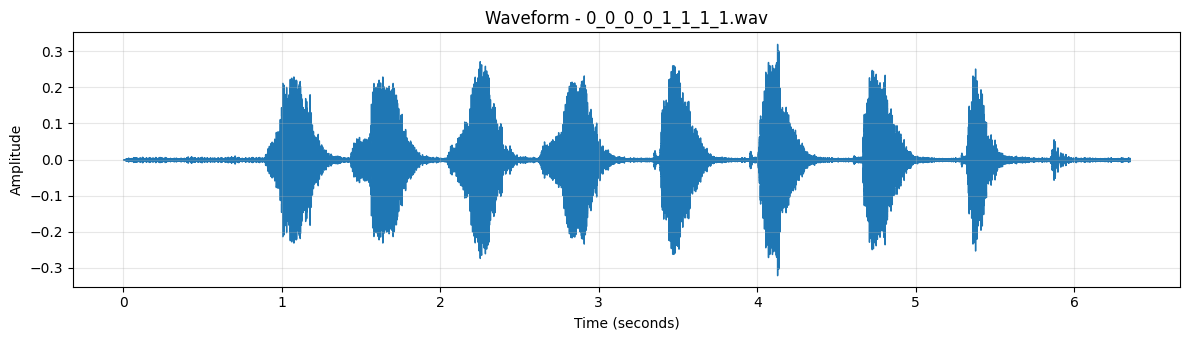

In [22]:
# ---------------------------------------------------------------
# 4.2 Waveform
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 3.5))
librosa.display.waveshow(y_example, sr=sr_example, ax=ax)
ax.set_title(f"Waveform - {os.path.basename(example_path)}")
ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Amplitude")
ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "01_waveform.png"), dpi=200)
plt.show()

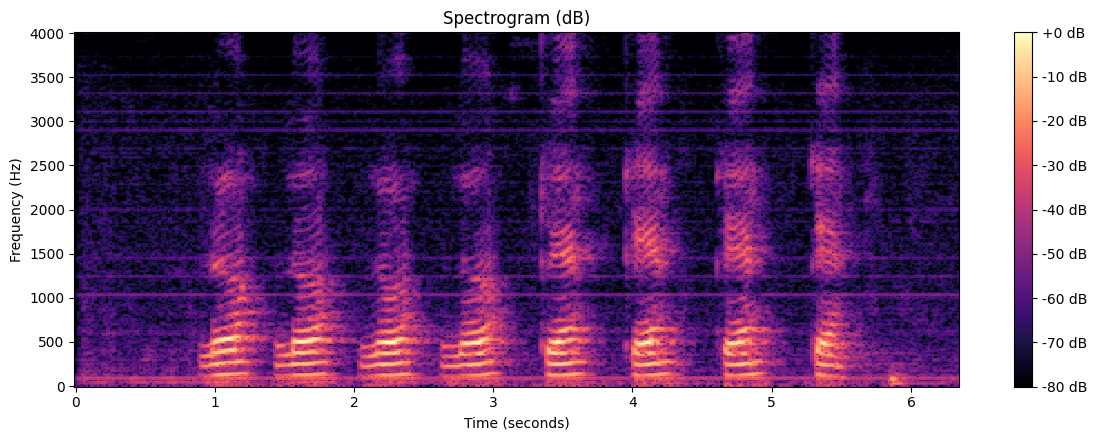

In [23]:
# ---------------------------------------------------------------
# 4.3 Spectrogram (STFT magnitude in dB)
# ---------------------------------------------------------------
stft = librosa.stft(y_example, n_fft=N_FFT, hop_length=HOP_LENGTH)
spec_db = librosa.amplitude_to_db(np.abs(stft), ref=np.max)

fig, ax = plt.subplots(figsize=(12, 4.5))
img = librosa.display.specshow(spec_db, sr=sr_example, hop_length=HOP_LENGTH,
                               x_axis="time", y_axis="hz", ax=ax)
fig.colorbar(img, ax=ax, format="%+2.0f dB")
ax.set_title("Spectrogram (dB)")
ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Frequency (Hz)")
plt.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "02_spectrogram.png"), dpi=200)
plt.show()

MFCC matrix shape (coefficients x frames): (13, 397)


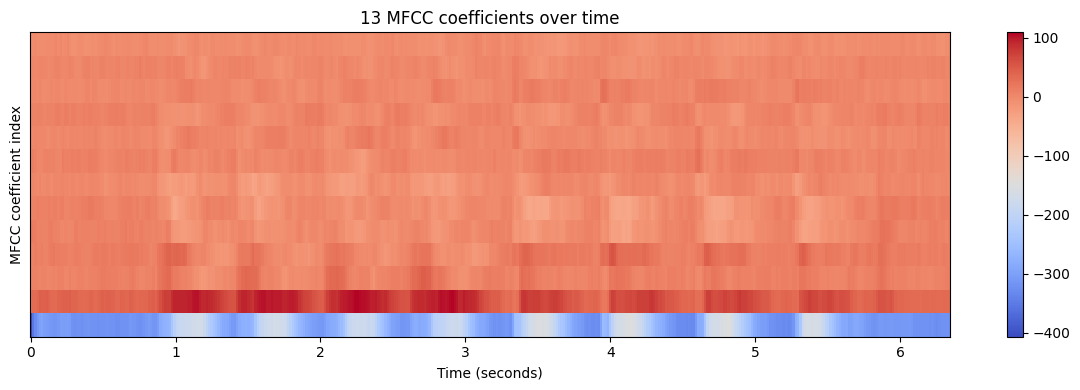

In [24]:
# ---------------------------------------------------------------
# 4.4 MFCC of the whole example recording (13 coefficients per frame)
# ---------------------------------------------------------------
mfcc_example = librosa.feature.mfcc(y=y_example, sr=sr_example, n_mfcc=N_MFCC,
                                    n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS)
print("MFCC matrix shape (coefficients x frames):", mfcc_example.shape)

fig, ax = plt.subplots(figsize=(12, 4))
img = librosa.display.specshow(mfcc_example, sr=sr_example, hop_length=HOP_LENGTH,
                               x_axis="time", ax=ax)
fig.colorbar(img, ax=ax)
ax.set_title("13 MFCC coefficients over time")
ax.set_xlabel("Time (seconds)")
ax.set_ylabel("MFCC coefficient index")
plt.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "03_mfcc.png"), dpi=200)
plt.show()

## 5. Audio Segmentation into Words

Each recording must be cut into its eight words. The function `librosa.effects.split()` finds the **non-silent intervals** of a signal. A frame is treated as non-silent if its energy is within `top_db` decibels of the loudest frame in the recording. The settings required by the assignment are:

| Parameter | Value | Meaning |
|---|---|---|
| `top_db` | 25 | Quieter than the peak by more than 25 dB = silence |
| `frame_length` | 512 | Samples per analysis frame |
| `hop_length` | 128 | Step between frames, in samples |

**Acceptance rule.** A recording is accepted only if exactly **eight** segments are found. Then the *i*-th segment can be matched with the *i*-th label in the file name. A recording with a different number of segments (two words merged, or one word split) is skipped, because the labels could no longer be matched safely.

Segments found in the example recording: 9


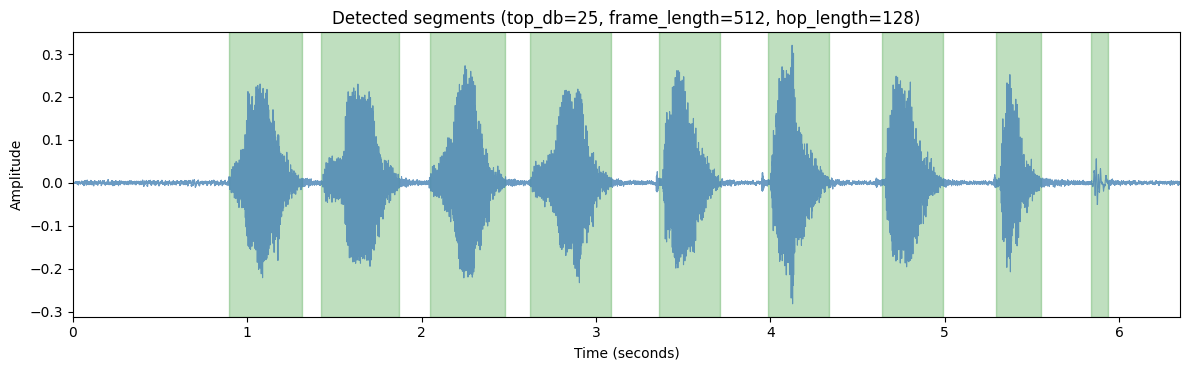

In [25]:
# ---------------------------------------------------------------
# 5.1 Segmentation function and demonstration on one recording
# ---------------------------------------------------------------
def segment_recording(signal):
    """Return an array of [start_sample, end_sample] for every non-silent interval."""
    return librosa.effects.split(signal, top_db=TOP_DB,
                                 frame_length=FRAME_LENGTH, hop_length=HOP_LENGTH)

demo_intervals = segment_recording(y_example)
print("Segments found in the example recording:", len(demo_intervals))

time_axis = np.arange(len(y_example)) / sr_example
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(time_axis, y_example, color="steelblue", alpha=0.8, linewidth=0.8)
for i, (start, end) in enumerate(demo_intervals):
    ax.axvspan(start / sr_example, end / sr_example, color="green", alpha=0.25)
    # Write the true label (from the file name) above each segment if counts agree
    if len(demo_intervals) == WORDS_PER_RECORDING:
        ax.text((start + end) / 2 / sr_example, ax.get_ylim()[1] * 0.85,
                CLASS_NAMES[example_labels[i]], ha="center", fontsize=10, fontweight="bold")
ax.set_title(f"Detected segments (top_db={TOP_DB}, frame_length={FRAME_LENGTH}, hop_length={HOP_LENGTH})")
ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Amplitude")
ax.set_xlim(0, time_axis[-1])
plt.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "04_segmentation_example.png"), dpi=200)
plt.show()

Original recordings : 60
Accepted recordings : 41 (exactly 8 segments)
Skipped recordings  : 19

Number of recordings for each detected segment count:


,recordings
n_segments,
4,1
6,2
7,5
8,41
9,7
10,2
11,1
13,1


Skipped recordings and the number of segments found:


,file,n_segments
0,0_0_0_0_1_1_1_1.wav,9
1,0_0_0_1_0_0_0_1.wav,9
2,0_0_1_0_1_0_0_1.wav,7
3,0_0_1_1_0_0_0_1.wav,9
4,0_0_1_1_1_0_0_0.wav,7
5,0_1_0_1_0_0_0_0.wav,7
6,0_1_0_1_1_1_0_0.wav,9
7,0_1_1_1_0_1_0_1.wav,10
8,0_1_1_1_1_0_1_0.wav,9
9,1_0_0_0_0_0_0_0.wav,9


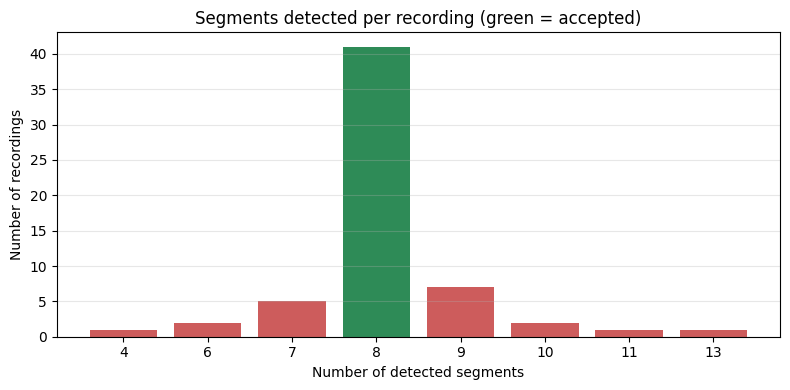

In [26]:
# ---------------------------------------------------------------
# 5.2 Segment every recording and decide which ones are accepted
# ---------------------------------------------------------------
recordings_df["n_segments"] = [len(segment_recording(audio_cache[p][0])) for p in recordings_df["path"]]
recordings_df["accepted"] = recordings_df["n_segments"] == WORDS_PER_RECORDING

accepted_files = recordings_df.loc[recordings_df["accepted"], "path"].tolist()
skipped_files = recordings_df.loc[~recordings_df["accepted"], "path"].tolist()
accepted_set = set(accepted_files)

print("Original recordings :", len(recordings_df))
print("Accepted recordings :", len(accepted_files), f"(exactly {WORDS_PER_RECORDING} segments)")
print("Skipped recordings  :", len(skipped_files))

print("\nNumber of recordings for each detected segment count:")
display(recordings_df["n_segments"].value_counts().sort_index().rename("recordings").to_frame())

if skipped_files:
    print("Skipped recordings and the number of segments found:")
    display(recordings_df.loc[~recordings_df["accepted"], ["file", "n_segments"]].reset_index(drop=True))

counts = recordings_df["n_segments"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 4))
colors = ["seagreen" if k == WORDS_PER_RECORDING else "indianred" for k in counts.index]
ax.bar(counts.index.astype(str), counts.values, color=colors)
ax.set_xlabel("Number of detected segments")
ax.set_ylabel("Number of recordings")
ax.set_title("Segments detected per recording (green = accepted)")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "05_segment_counts.png"), dpi=200)
plt.show()

if len(accepted_files) == 0:
    raise RuntimeError("No recording was accepted. Check the segmentation settings.")

## 6. Recording-Level Train/Test Split

The eight words of one recording share the same speaker, microphone and acoustic conditions. If the words were split randomly, words from the **same recording** could appear in both the training and the test set. The model could then profit from recording-specific characteristics, and the test accuracy would be too optimistic.

To avoid this, the **original recording files are split first** (75 % training, 25 % testing, `random_state=42`). Word segments are extracted **only afterwards**, separately inside each group. The split is applied to all 60 original files; skipped recordings are then simply ignored during feature extraction.

In [27]:
# ---------------------------------------------------------------
# 6.1 Split the ORIGINAL recording files (before any word extraction)
# ---------------------------------------------------------------
train_files, test_files = train_test_split(wav_files, test_size=TEST_SIZE, random_state=RANDOM_STATE)

# Safety check: no recording may appear in both sets
assert set(train_files).isdisjoint(set(test_files)), "Leakage: a recording is in both sets!"

split_summary = pd.DataFrame({
    "Original recordings": [len(train_files), len(test_files)],
    "Accepted (8 segments)": [sum(p in accepted_set for p in train_files),
                              sum(p in accepted_set for p in test_files)],
    "Skipped": [sum(p not in accepted_set for p in train_files),
                sum(p not in accepted_set for p in test_files)],
}, index=["Training", "Testing"])
display(split_summary)
print("No recording is shared between training and testing: OK")

,Original recordings,Accepted (8 segments),Skipped
Training,45,31,14
Testing,15,10,5


No recording is shared between training and testing: OK


## 7. Feature Extraction and Dataset Statistics

For every word segment the notebook computes 13 MFCCs for each frame, and then summarises the word with

* the **mean** of each coefficient over time (13 values), and
* the **standard deviation** of each coefficient over time (13 values).

This gives a fixed-length vector of **26 features per word**, no matter how long the word is. The label of each word is taken from the file name, using the order of the segments.

In [28]:
# ---------------------------------------------------------------
# 7.1 Feature extraction for each word segment
# ---------------------------------------------------------------
feature_names = [f"mfcc{i}_mean" for i in range(1, N_MFCC + 1)] + \
                [f"mfcc{i}_std" for i in range(1, N_MFCC + 1)]

def extract_word_features(segment, sr):
    """26 features: mean and std of 13 MFCCs computed over the frames of one word."""
    mfcc = librosa.feature.mfcc(y=segment, sr=sr, n_mfcc=N_MFCC,
                                n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS)
    return np.concatenate([mfcc.mean(axis=1), mfcc.std(axis=1)])

def build_dataset(files):
    """Create (X, y, meta) from the ACCEPTED recordings among `files`."""
    X, y, meta = [], [], []
    for path in files:
        if path not in accepted_set:
            continue                                   # skipped recording
        signal, sr = audio_cache[path]
        intervals = segment_recording(signal)
        labels = parse_labels(path)
        for position, ((start, end), label) in enumerate(zip(intervals, labels), start=1):
            X.append(extract_word_features(signal[start:end], sr))
            y.append(label)
            meta.append({"file": os.path.basename(path), "word_position": position})
    return np.array(X), np.array(y), pd.DataFrame(meta)

X_train, y_train, meta_train = build_dataset(train_files)
X_test,  y_test,  meta_test  = build_dataset(test_files)

print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test :", X_test.shape,  "| y_test :", y_test.shape)

# The two sets must not share any recording file
assert set(meta_train["file"]).isdisjoint(set(meta_test["file"])), "Leakage between train and test!"

/usr/local/lib/python3.13/dist-packages/librosa/core/spectrum.py:266: UserWarning: n_fft=512 is too large for input signal of length=384
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/librosa/core/spectrum.py:266: UserWarning: n_fft=512 is too large for input signal of length=256
  warnings.warn(


X_train: (248, 26) | y_train: (248,)
X_test : (80, 26) | y_test : (80,)


Total word samples      : 328
Training word samples   : 248
Testing word samples    : 80
Features per word       : 26

Class distribution:


,Total,Training,Testing,Total %
No,152,115,37,46.34
Yes,176,133,43,53.66



Missing values (NaN) in the feature table: 0
All feature values finite (no inf/NaN)  : True

Summary statistics of the 26 features:


,count,mean,std,min,25%,50%,75%,max
mfcc1_mean,328.0,-211.038,15.443,-294.185,-220.070,-210.338,-200.576,-179.214
mfcc2_mean,328.0,76.813,11.824,32.351,67.198,73.243,88.632,99.542
mfcc3_mean,328.0,14.064,5.260,1.345,10.231,14.133,17.702,30.089
mfcc4_mean,328.0,16.944,11.468,-2.792,6.357,20.140,27.333,38.044
mfcc5_mean,328.0,-10.431,7.970,-25.916,-17.473,-10.938,-3.437,11.443
mfcc6_mean,328.0,-12.878,6.660,-29.658,-18.245,-13.520,-7.475,14.347
mfcc7_mean,328.0,-6.964,8.822,-25.460,-15.289,-4.205,0.743,8.906
mfcc8_mean,328.0,3.084,4.484,-8.333,-0.666,3.246,6.451,12.754
mfcc9_mean,328.0,-1.198,5.973,-14.952,-5.998,-1.362,4.272,10.333
mfcc10_mean,328.0,-2.025,2.707,-8.781,-3.778,-2.207,-0.470,8.268


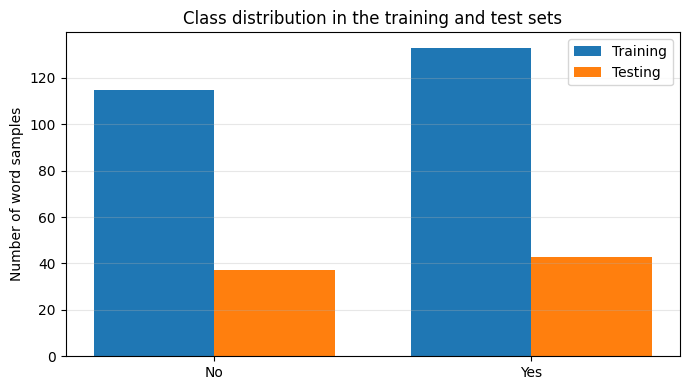

In [29]:
# ---------------------------------------------------------------
# 7.2 Dataset statistics, class distribution and missing-value checks
# ---------------------------------------------------------------
X_all = np.vstack([X_train, X_test])
y_all = np.concatenate([y_train, y_test])
features_df = pd.DataFrame(X_all, columns=feature_names)

print("Total word samples      :", len(y_all))
print("Training word samples   :", len(y_train))
print("Testing word samples    :", len(y_test))
print("Features per word       :", X_all.shape[1])

# ----- Class distribution -----
dist = pd.DataFrame({
    "Total": pd.Series(y_all).value_counts(),
    "Training": pd.Series(y_train).value_counts(),
    "Testing": pd.Series(y_test).value_counts(),
}).reindex([0, 1]).fillna(0).astype(int)
dist.index = [CLASS_NAMES[i] for i in dist.index]
dist["Total %"] = (dist["Total"] / dist["Total"].sum() * 100).round(2)
print("\nClass distribution:")
display(dist)

if (np.bincount(y_test, minlength=2) == 0).any():
    print("WARNING: one class is missing from the test set.")

# ----- Missing / invalid values -----
print("\nMissing values (NaN) in the feature table:", int(features_df.isna().sum().sum()))
print("All feature values finite (no inf/NaN)  :", bool(np.isfinite(X_all).all()))

# ----- Summary statistics of the features -----
print("\nSummary statistics of the 26 features:")
display(features_df.describe().T.round(3))

# ----- Class distribution plot -----
fig, ax = plt.subplots(figsize=(7, 4))
x_pos = np.arange(len(dist))
width = 0.38
ax.bar(x_pos - width / 2, dist["Training"], width, label="Training")
ax.bar(x_pos + width / 2, dist["Testing"], width, label="Testing")
ax.set_xticks(x_pos)
ax.set_xticklabels(dist.index)
ax.set_ylabel("Number of word samples")
ax.set_title("Class distribution in the training and test sets")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "06_class_distribution.png"), dpi=200)
plt.show()

## 8. Classification Models

Four different classifiers are trained on the same training data and evaluated on the same test data. Standardisation (`StandardScaler`) is placed **inside a pipeline**, so the mean and the standard deviation are learned from the training data only and then applied to the test data.

**Support Vector Machine (SVM, RBF kernel).** An SVM looks for the decision boundary with the largest margin between the classes. The RBF kernel lets the boundary be non-linear. It works well on small datasets with continuous features, but it needs scaled features.

**Neural Network (MLPClassifier).** A multilayer perceptron with two hidden layers (64 and 32 neurons), ReLU activation and the Adam optimiser. It learns non-linear combinations of the features. It needs scaled inputs and can be sensitive to the random initialisation, which is why the seed is fixed.

**Random Forest (100 trees).** An ensemble of decision trees, each trained on a random sample of the data and features. The final decision is a majority vote. It does not need feature scaling and is robust to noise, so no scaler is used.

**K-Nearest Neighbours (KNN, k = 5).** A new word is given the majority label of its five closest training words. Because it relies on distances, scaling the features is essential.

In [30]:
# ---------------------------------------------------------------
# 8.1 Define the four models
# ---------------------------------------------------------------
models = {
    "SVM (RBF)": make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", random_state=RANDOM_STATE)),

    "Neural Network (MLP)": make_pipeline(
        StandardScaler(),
        MLPClassifier(hidden_layer_sizes=(64, 32), activation="relu", solver="adam",
                      max_iter=1000, random_state=RANDOM_STATE)),

    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE),

    "KNN (k=5)": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)),
}

for name, model in models.items():
    print(f"{name:22s} -> {model}")

SVM (RBF)              -> Pipeline(steps=[('standardscaler', StandardScaler()),
                ('svc', SVC(random_state=42))])
Neural Network (MLP)   -> Pipeline(steps=[('standardscaler', StandardScaler()),
                ('mlpclassifier',
                 MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=1000,
                               random_state=42))])
Random Forest          -> RandomForestClassifier(random_state=42)
KNN (k=5)              -> Pipeline(steps=[('standardscaler', StandardScaler()),
                ('kneighborsclassifier', KNeighborsClassifier())])


## 9. Training and Evaluation

For every model the notebook computes, **on the test set only**:

* **Accuracy** – share of correctly classified words.
* **Precision, Recall and F1-score** – reported as the **macro average** over the two classes (each class has the same weight). The per-class values are in the classification report.
* **Classification report** and **confusion matrix**.

The test words are never used for training or scaling.

In [31]:
# ---------------------------------------------------------------
# 9.1 Train every model and evaluate it on the test set
# ---------------------------------------------------------------
results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)                 # training on the training set only
    y_pred = model.predict(X_test)              # prediction on the unseen test set
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy (%)":        100 * accuracy_score(y_test, y_pred),
        "Precision macro (%)": 100 * precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall macro (%)":    100 * recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1 macro (%)":        100 * f1_score(y_test, y_pred, average="macro", zero_division=0),
    })

    print("=" * 70)
    print(name)
    print("=" * 70)
    print(classification_report(y_test, y_pred, labels=[0, 1],
                                target_names=[CLASS_NAMES[0], CLASS_NAMES[1]], zero_division=0))

results_df = pd.DataFrame(results).set_index("Model").round(2)
print("Summary of all models (test set):")
display(results_df)

SVM (RBF)
              precision    recall  f1-score   support

          No       1.00      1.00      1.00        37
         Yes       1.00      1.00      1.00        43

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80

Neural Network (MLP)
              precision    recall  f1-score   support

          No       1.00      1.00      1.00        37
         Yes       1.00      1.00      1.00        43

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80

Random Forest
              precision    recall  f1-score   support

          No       1.00      1.00      1.00        37
         Yes       1.00      1.00      1.00        43

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      

,Accuracy (%),Precision macro (%),Recall macro (%),F1 macro (%)
Model,,,,
SVM (RBF),100.0,100.0,100.0,100.0
Neural Network (MLP),100.0,100.0,100.0,100.0
Random Forest,100.0,100.0,100.0,100.0
KNN (k=5),100.0,100.0,100.0,100.0


## 10. Visualisation of Results

A **confusion matrix** shows how many words of each true class were predicted as each class. The diagonal contains the correct predictions; the off-diagonal cells are the errors. The four matrices below are on the same test set.

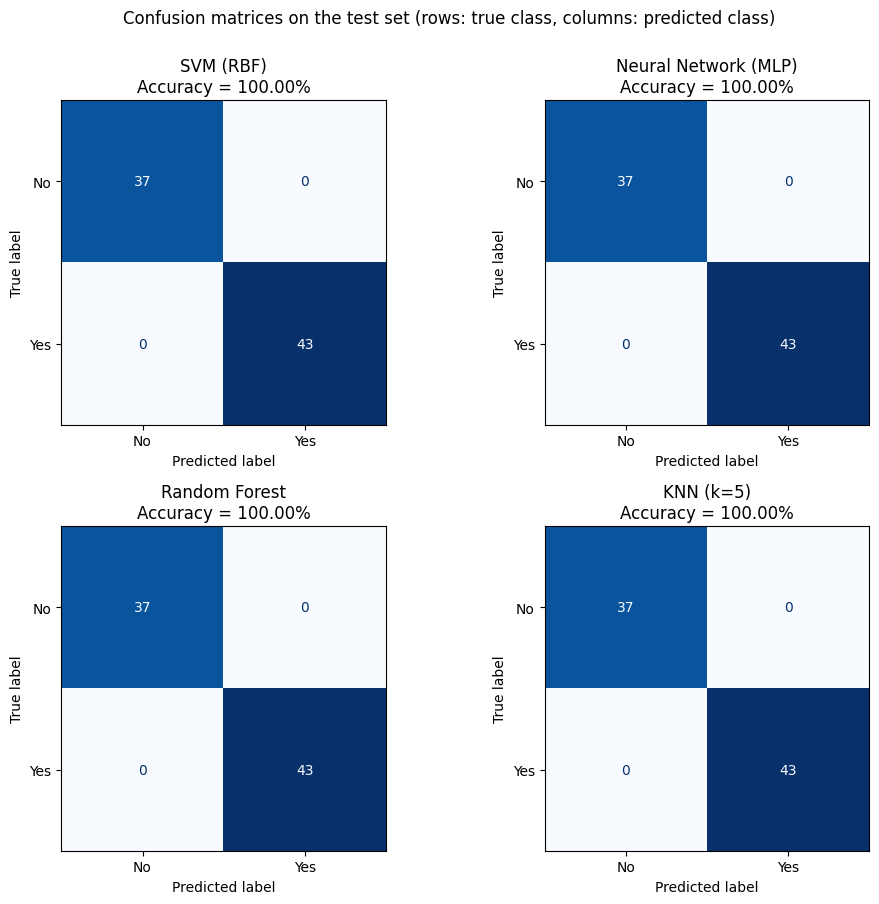

In [32]:
# ---------------------------------------------------------------
# 10.1 Four confusion matrices in a 2 x 2 layout
# ---------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for ax, (name, y_pred) in zip(axes.ravel(), predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=[CLASS_NAMES[0], CLASS_NAMES[1]]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    acc = 100 * accuracy_score(y_test, y_pred)
    ax.set_title(f"{name}\nAccuracy = {acc:.2f}%")
fig.suptitle("Confusion matrices on the test set (rows: true class, columns: predicted class)", y=1.00)
plt.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "07_confusion_matrices.png"), dpi=300, bbox_inches="tight")
plt.show()

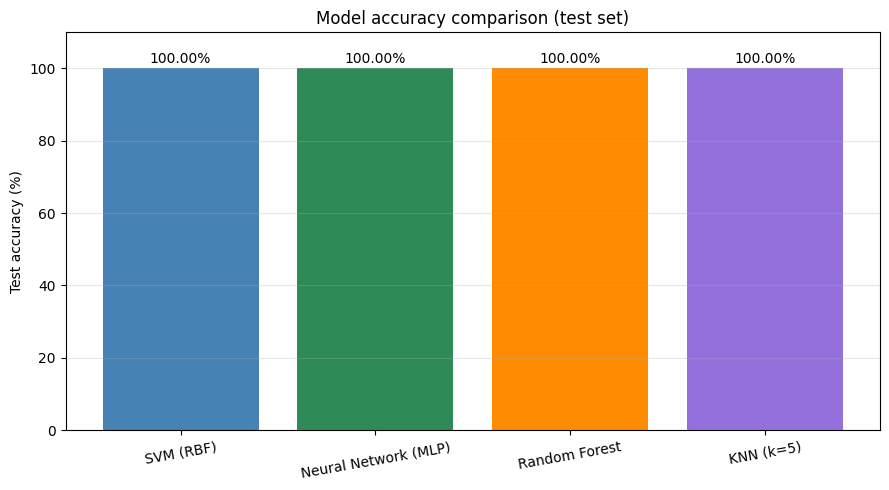

In [33]:
# ---------------------------------------------------------------
# 10.2 Model accuracy comparison chart
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(results_df.index, results_df["Accuracy (%)"],
              color=["steelblue", "seagreen", "darkorange", "mediumpurple"])
ax.set_ylabel("Test accuracy (%)")
ax.set_title("Model accuracy comparison (test set)")
ax.set_ylim(0, 110)
for bar, value in zip(bars, results_df["Accuracy (%)"]):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 1.5, f"{value:.2f}%", ha="center")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=10)
plt.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "08_accuracy_comparison.png"), dpi=300)
plt.show()

## 11. Results and Comparison

The cell below reads the results computed above and prints a short summary. The text is generated from the actual numbers, so it stays correct if the data, the split or the parameters are changed. The table and the confusion matrices in Sections 9 and 10 are the primary evidence.

When reading the results, keep in mind that the test set is **small**: one misclassified word changes the accuracy by a visible amount (shown below). Differences of one or two words between models are therefore **not** strong evidence that one model is better than another.

In [34]:
# ---------------------------------------------------------------
# 11.1 Automatic summary of the results + saving the tables
# ---------------------------------------------------------------
n_test_words = len(y_test)
n_test_recordings = meta_test["file"].nunique()
n_train_recordings = meta_train["file"].nunique()

print(f"Training set : {len(y_train)} words from {n_train_recordings} accepted recordings")
print(f"Test set     : {n_test_words} words from {n_test_recordings} accepted recordings")
print(f"One misclassified test word changes the accuracy by {100 / n_test_words:.2f} percentage points.\n")

best_acc = results_df["Accuracy (%)"].max()
best_models = results_df.index[results_df["Accuracy (%)"] == best_acc].tolist()
worst_acc = results_df["Accuracy (%)"].min()

print(f"Highest test accuracy : {best_acc:.2f}%  ->  {', '.join(best_models)}")
print(f"Lowest test accuracy  : {worst_acc:.2f}%")

for name, y_pred in predictions.items():
    errors = int((y_pred != y_test).sum())
    print(f"  {name:22s}: {errors} misclassified word(s) out of {n_test_words}")

if (results_df["Accuracy (%)"] == 100).all():
    print("\nAll models reached 100% accuracy on this test set. This shows that the task is easy for "
          "these features, but with so few test words it cannot rank the models. "
          "See the limitations section.")
elif len(best_models) > 1:
    print("\nSeveral models share the best accuracy; the test set is too small to separate them.")

# ----- Save the result tables -----
results_df.to_csv(os.path.join(RESULTS_DIR, "model_results.csv"))
dist.to_csv(os.path.join(RESULTS_DIR, "class_distribution.csv"))
recordings_df.drop(columns="path").to_csv(os.path.join(RESULTS_DIR, "recordings_summary.csv"), index=False)
print(f"\nTables and figures saved in the '{RESULTS_DIR}' folder.")

Training set : 248 words from 31 accepted recordings
Test set     : 80 words from 10 accepted recordings
One misclassified test word changes the accuracy by 1.25 percentage points.

Highest test accuracy : 100.00%  ->  SVM (RBF), Neural Network (MLP), Random Forest, KNN (k=5)
Lowest test accuracy  : 100.00%
  SVM (RBF)             : 0 misclassified word(s) out of 80
  Neural Network (MLP)  : 0 misclassified word(s) out of 80
  Random Forest         : 0 misclassified word(s) out of 80
  KNN (k=5)             : 0 misclassified word(s) out of 80

All models reached 100% accuracy on this test set. This shows that the task is easy for these features, but with so few test words it cannot rank the models. See the limitations section.

Tables and figures saved in the 'results' folder.


## 12. Limitations

* **Very small dataset.** The dataset has only 60 recordings, and only those with exactly eight detected segments are used. The test set is therefore small, and a single error changes the accuracy noticeably.
* **Single split.** The results come from one train/test split with one random seed. No cross-validation or repeated splits were used, so no confidence intervals are available.
* **Selection effect of the segmentation.** Recordings whose segment count is not eight are skipped. Those recordings may be harder (for example, with pauses that are too short or too long), so the reported performance may not hold for all recordings.
* **Label alignment by order.** The *i*-th segment is assumed to be the *i*-th word in the file name. If two errors cancel out (one word split and two words merged), a recording can still have eight segments with wrong boundaries. The notebook does not check this manually.
* **Simple, controlled data.** The dataset is, according to its description, recorded by one speaker, with two Hebrew words and low noise. The results do not show how the models behave with several speakers, other words, background noise or other languages.
* **Simple features.** Taking the mean and the standard deviation of the MFCCs removes the temporal order of the frames. This is sufficient for this easy task, but it is a limitation for harder ones.
* **Fixed hyperparameters.** The models use the settings required by the assignment and were not tuned. The MFCC settings `n_fft = 512` and `n_mels = 40` were chosen by the author of this notebook for 8 kHz audio and are not part of the assignment.
* **Very high scores need careful interpretation.** If all models reach the same very high accuracy, the task is easy for these features, but the small test set cannot distinguish the models.